<a href="https://colab.research.google.com/github/Handdyy11/Electricity_load_forecasting/blob/main/Electricity_forcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.weightstats import ztest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")              # hide non-critical warnings to keep output clean
sns.set_style("whitegrid")                     # clean plot style
plt.rcParams["figure.figsize"] = (12, 4)       # default plot size
pd.set_option("display.max_columns", 50)       # show all columns when printing tables

In [34]:
url = "https://raw.githubusercontent.com/Handdyy11/Electricity_load_forecasting/main/load_data.csv"
df = pd.read_csv(url)
df.head()

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0,0,0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0,0,0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0,0,0


In [35]:
df.info()
print("Columns:", list(df.columns))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48048 entries, 0 to 48047
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    48048 non-null  object 
 1   nat_demand  48048 non-null  float64
 2   T2M_toc     48048 non-null  float64
 3   QV2M_toc    48048 non-null  float64
 4   TQL_toc     48048 non-null  float64
 5   W2M_toc     48048 non-null  float64
 6   T2M_san     48048 non-null  float64
 7   QV2M_san    48048 non-null  float64
 8   TQL_san     48048 non-null  float64
 9   W2M_san     48048 non-null  float64
 10  T2M_dav     48048 non-null  float64
 11  QV2M_dav    48048 non-null  float64
 12  TQL_dav     48048 non-null  float64
 13  W2M_dav     48048 non-null  float64
 14  Holiday_ID  48048 non-null  int64  
 15  holiday     48048 non-null  int64  
 16  school      48048 non-null  int64  
dtypes: float64(13), int64(3), object(1)
memory usage: 6.2+ MB
Columns: ['datetime', 'nat_demand', 'T2M_toc', 'Q

In [36]:
df["datetime"] = pd.to_datetime(df["datetime"])         # text -> real datetime type
df = df.sort_values("datetime").reset_index(drop=True)  # time series must be in time order

dups = df.duplicated(subset="datetime").sum()           # count repeated timestamps
print("Duplicate timestamps:", dups)
df = df.drop_duplicates(subset="datetime", keep="first").reset_index(drop=True)

print("Period:", df["datetime"].min(), "to", df["datetime"].max())
print("Rows  :", len(df))

Duplicate timestamps: 0
Period: 2015-01-03 01:00:00 to 2020-06-27 00:00:00
Rows  : 48048


In [37]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

# A complete hourly timeline from first to last timestamp
full_range = pd.date_range(df["datetime"].min(), df["datetime"].max(), freq="h")
missing_hours = full_range.difference(df["datetime"])   # hours that should exist but do not
print("\nExpected hourly rows:", len(full_range))
print("Actual rows         :", len(df))
print("Missing hours       :", len(missing_hours))

Missing values per column:
No missing values

Expected hourly rows: 48048
Actual rows         : 48048
Missing hours       : 0


In [38]:
# The data has no missing values, no duplicates and no missing hours, so no filling is needed.
TARGET = "nat_demand"                                    # electricity load in MW (variable to forecast)
flag_cols = ["Holiday_ID", "holiday", "school"]          # calendar flags
weather_cols = [c for c in df.columns if c not in flag_cols + ["datetime", TARGET]]   # 12 weather variables

In [39]:
# Reported only, not removed - extreme load can be genuine
# IQR rule: a value is an outlier if it lies more than 1.5*IQR outside the quartiles
cols = [TARGET] + weather_cols
q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
iqr = q3 - q1
n_out = ((df[cols] < q1 - 1.5 * iqr) | (df[cols] > q3 + 1.5 * iqr)).sum()
n_out.to_frame("n_outliers").assign(pct=(100 * n_out / len(df)).round(2))

,n_outliers,pct
nat_demand,7,0.01
T2M_toc,226,0.47
QV2M_toc,183,0.38
TQL_toc,850,1.77
W2M_toc,55,0.11
T2M_san,1292,2.69
QV2M_san,410,0.85
TQL_san,741,1.54
W2M_san,899,1.87
T2M_dav,889,1.85


In [40]:
print("Skewness of demand:", round(df[TARGET].skew(), 3))          # 0 = symmetric
df[cols].describe().T.round(3)                                     # mean, std, min, quartiles, max

Skewness of demand: 0.248


,count,mean,std,min,25%,50%,75%,max
nat_demand,48048.0,1182.869,192.069,85.193,1020.057,1168.428,1327.564,1754.882
T2M_toc,48048.0,27.399,1.675,22.953,26.160,27.118,28.558,35.040
QV2M_toc,48048.0,0.018,0.002,0.012,0.017,0.019,0.020,0.023
TQL_toc,48048.0,0.080,0.066,0.000,0.026,0.065,0.117,0.521
W2M_toc,48048.0,13.391,7.296,0.009,7.545,12.182,18.661,39.230
T2M_san,48048.0,26.921,3.018,19.765,24.769,26.167,28.712,39.063
QV2M_san,48048.0,0.018,0.002,0.010,0.017,0.018,0.019,0.022
TQL_san,48048.0,0.106,0.086,0.000,0.037,0.086,0.157,0.485
W2M_san,48048.0,7.047,4.104,0.060,3.955,5.993,9.410,24.484
T2M_dav,48048.0,24.720,2.414,19.934,22.955,24.002,26.243,34.216


In [41]:
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek                      # 0 = Monday ... 6 = Sunday
df["month"] = df["datetime"].dt.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)              # 1 = Saturday/Sunday
df["season"] = np.where(df["month"].isin([1, 2, 3, 4]), "dry", "wet")   # Panama: dry Jan-Apr, wet May-Dec

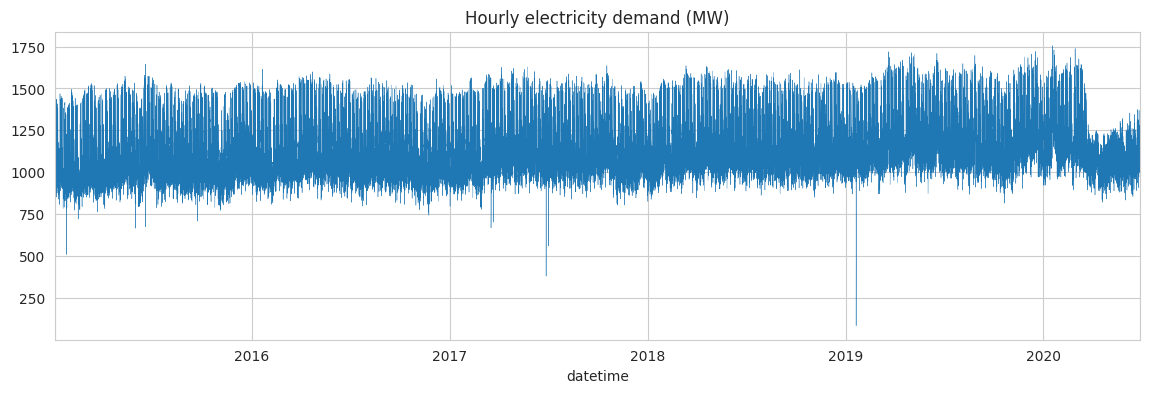

In [42]:
df.plot(x="datetime", y=TARGET, linewidth=0.3, figsize=(14, 4), legend=False, title="Hourly electricity demand (MW)")
plt.show()

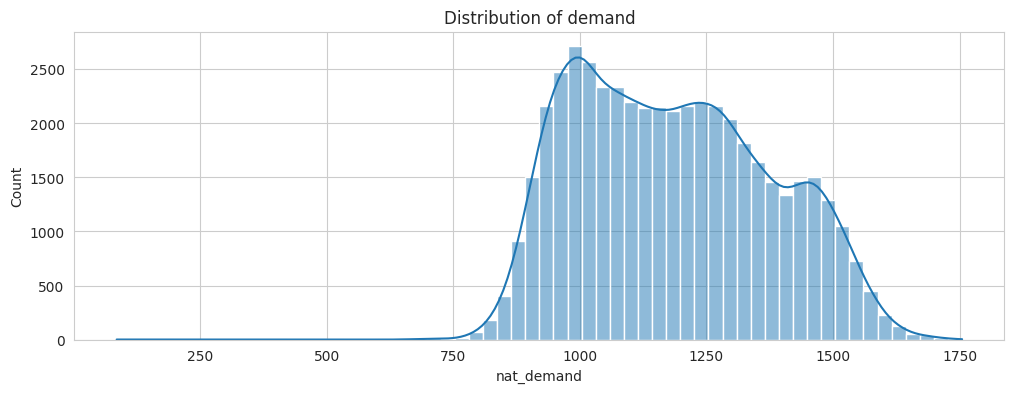

In [43]:
sns.histplot(df[TARGET], bins=60, kde=True)
plt.title("Distribution of demand")
plt.show()

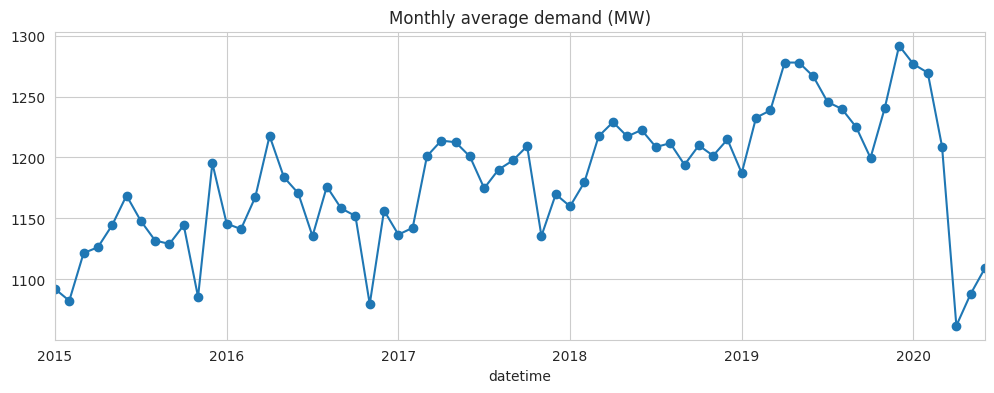

In [44]:
df.set_index("datetime")[TARGET].resample("MS").mean().plot(marker="o", title="Monthly average demand (MW)")
plt.show()

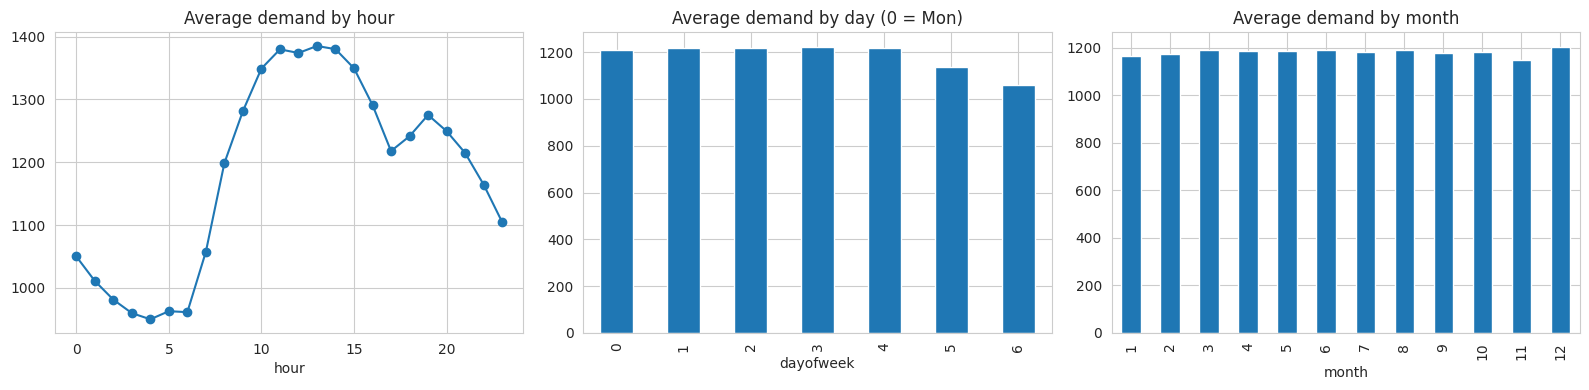

In [45]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("hour")[TARGET].mean().plot(ax=ax[0], marker="o", title="Average demand by hour")
df.groupby("dayofweek")[TARGET].mean().plot(kind="bar", ax=ax[1], title="Average demand by day (0 = Mon)")
df.groupby("month")[TARGET].mean().plot(kind="bar", ax=ax[2], title="Average demand by month")
plt.tight_layout(); plt.show()

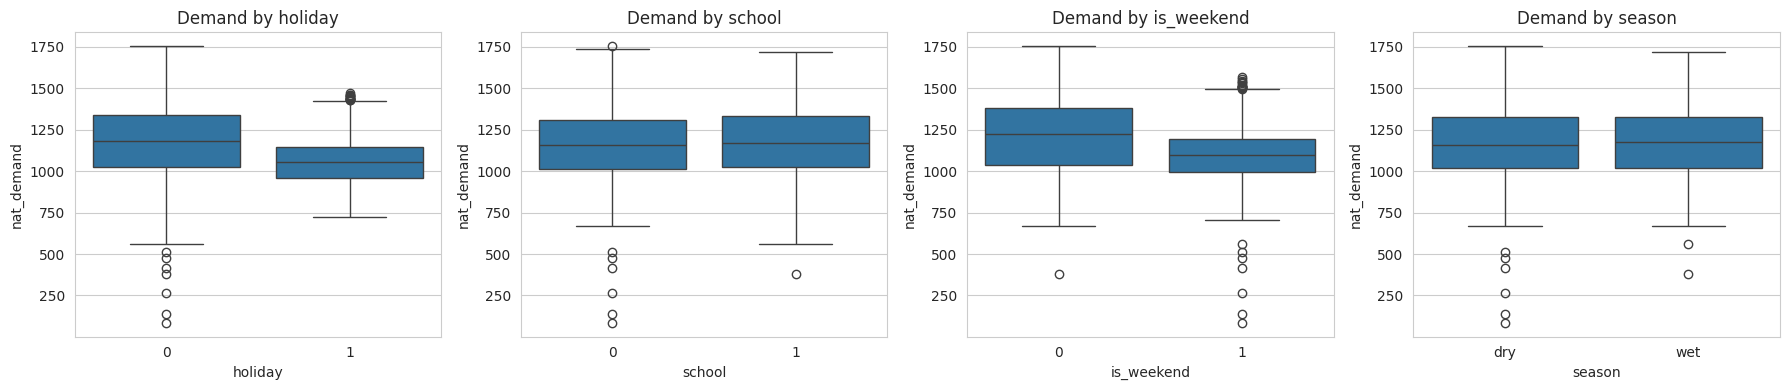

In [46]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, ["holiday", "school", "is_weekend", "season"]):
    sns.boxplot(x=c, y=TARGET, data=df, ax=a)
    a.set_title(f"Demand by {c}")
plt.tight_layout(); plt.show()

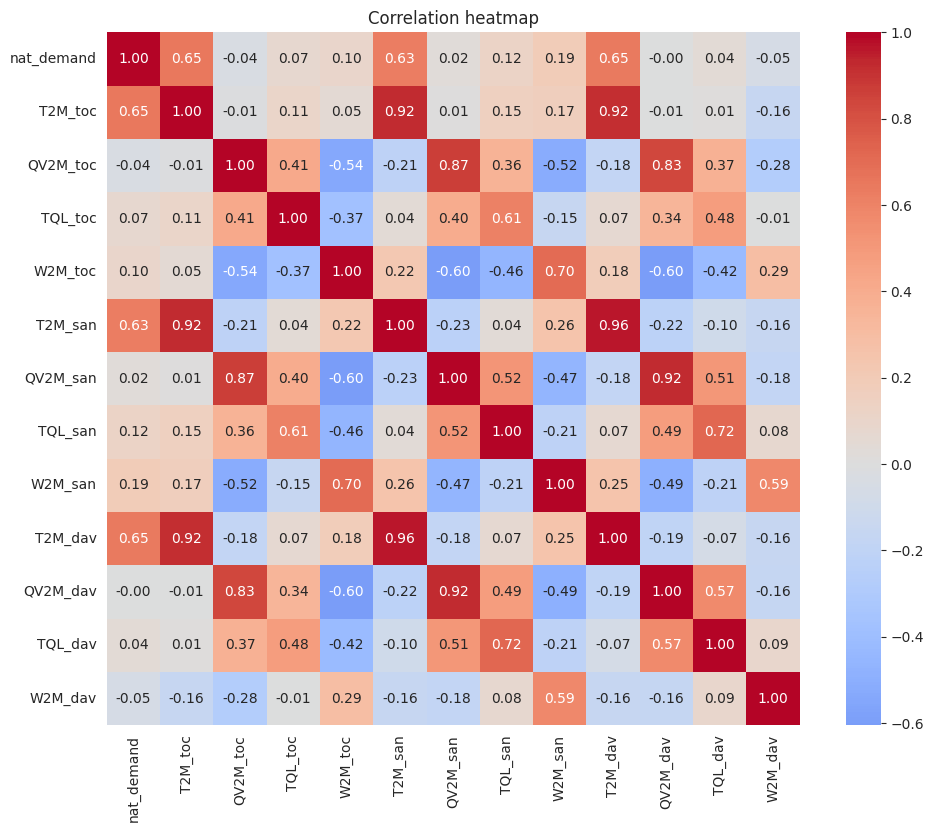

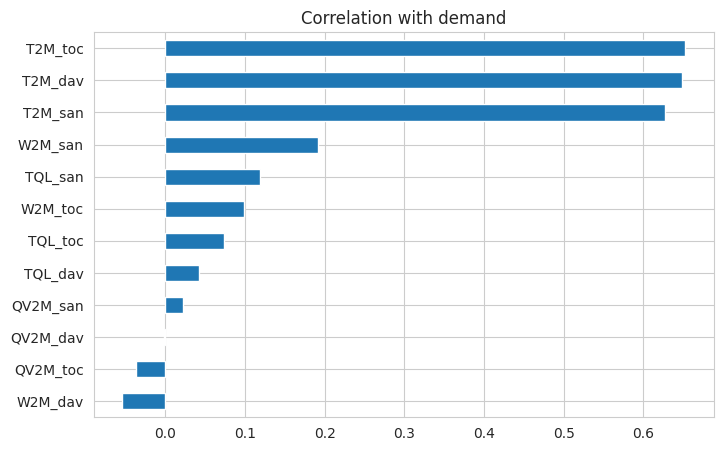

In [47]:
corr = df[cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.show()

corr[TARGET].drop(TARGET).sort_values().plot(kind="barh", figsize=(8, 5), title="Correlation with demand")
plt.show()

In [48]:
# shift(1) before rolling means the current hour is never used (no data leakage)
for h in (1, 24, 168):                                             # 1 hour, 1 day, 1 week ago
    df[f"lag_{h}"] = df[TARGET].shift(h)
for w in (24, 168):                                                # mean of previous day / week
    df[f"roll_mean_{w}"] = df[TARGET].shift(1).rolling(w).mean()
df = df.dropna().reset_index(drop=True)                            # first 168 rows have no lag_168

In [49]:
# Split by time, never shuffle a time series
df["set"] = np.where(df["datetime"] < "2020-01-01", "train", "test")
print(df["set"].value_counts())

set
train    43607
test      4273
Name: count, dtype: int64


In [50]:
# Then upload clean_data.csv to the repo's data/ folder
df.to_csv("clean_data.csv", index=False)
from google.colab import files
files.download("clean_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

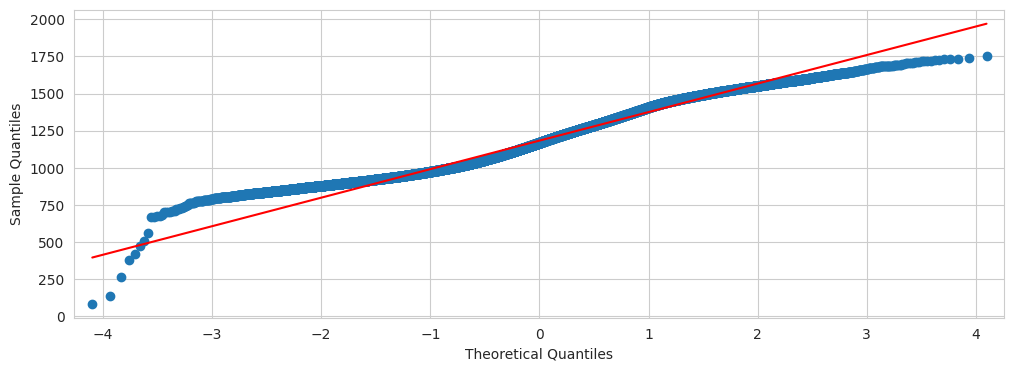

Normality test p-value: 1.9550069334368987e-86


In [51]:
import statsmodels.api as sm
# With ~48,000 rows the Central Limit Theorem makes mean-based tests reliable even if not perfectly normal
sm.qqplot(df[TARGET], line="s")                                    # points on the line = normal
plt.show()
print("Normality test p-value:", stats.normaltest(df[TARGET].sample(5000, random_state=42))[1])

In [52]:
# Welch t-test (does not assume equal variances). H0: mean demand is the same in both groups
p_vals = {}                                                        # collects p-values for the summary table
for col in ["holiday", "school"]:
    a, b = df.loc[df[col] == 1, TARGET], df.loc[df[col] == 0, TARGET]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    p_vals[f"t-test: {col} vs not"] = p
    print(f"{col}: mean(1)={a.mean():.2f}, mean(0)={b.mean():.2f}, t={t:.3f}, p={p:.4g}")

holiday: mean(1)=1060.57, mean(0)=1191.38, t=-50.842, p=0
school: mean(1)=1187.57, mean(0)=1171.31, t=8.289, p=1.206e-16


In [53]:
# Two-sample z-test (valid because n is very large): dry vs wet season
dry = df.loc[df["season"] == "dry", TARGET]
wet = df.loc[df["season"] == "wet", TARGET]
z, p = ztest(dry, wet)
p_vals["z-test: dry vs wet"] = p
print(f"dry mean={dry.mean():.2f}, wet mean={wet.mean():.2f}, z={z:.3f}, p={p:.4g}")

dry mean=1181.63, wet mean=1184.05, z=-1.320, p=0.1868


In [54]:
# F = variance(dry) / variance(wet); H0: variances are equal
def f_test(x, y):
    F = np.var(x, ddof=1) / np.var(y, ddof=1)
    dfn, dfd = len(x) - 1, len(y) - 1
    return F, 2 * min(stats.f.cdf(F, dfn, dfd), stats.f.sf(F, dfn, dfd))   # two-tailed p-value

F, p = f_test(dry, wet)
p_vals["F-test: variance dry vs wet"] = p
print(f"F={F:.3f}, p={p:.4g}")

F=1.079, p=1.842e-08


In [58]:
F_a, p_a = stats.f_oneway(*[g[TARGET] for _, g in df.groupby("month")])   # do monthly means differ?
ols = sm.OLS(df[TARGET], sm.add_constant(df[weather_cols])).fit()         # do weather variables explain demand?
p_vals["ANOVA F-test: months"] = p_a
p_vals["Regression F-test: weather"] = ols.f_pvalue
print(f"ANOVA: F={F_a:.2f}, p={p_a:.4g}")
print(f"Regression: F={ols.fvalue:.2f}, p={ols.f_pvalue:.4g}, R-squared={ols.rsquared:.3f}")

ANOVA: F=20.31, p=1.254e-41
Regression: F=3480.52, p=0, R-squared=0.466


In [59]:
summary = pd.Series(p_vals, name="p-value").to_frame()
summary["Decision (5%)"] = np.where(summary["p-value"] < 0.05, "Reject H0", "Fail to reject H0")
summary

,p-value,Decision (5%)
t-test: holiday vs not,0.000000e+00,Reject H0
t-test: school vs not,1.206417e-16,Reject H0
z-test: dry vs wet,1.867865e-01,Fail to reject H0
F-test: variance dry vs wet,1.841581e-08,Reject H0
ANOVA F-test: months,1.253923e-41,Reject H0
Regression F-test: weather,0.000000e+00,Reject H0


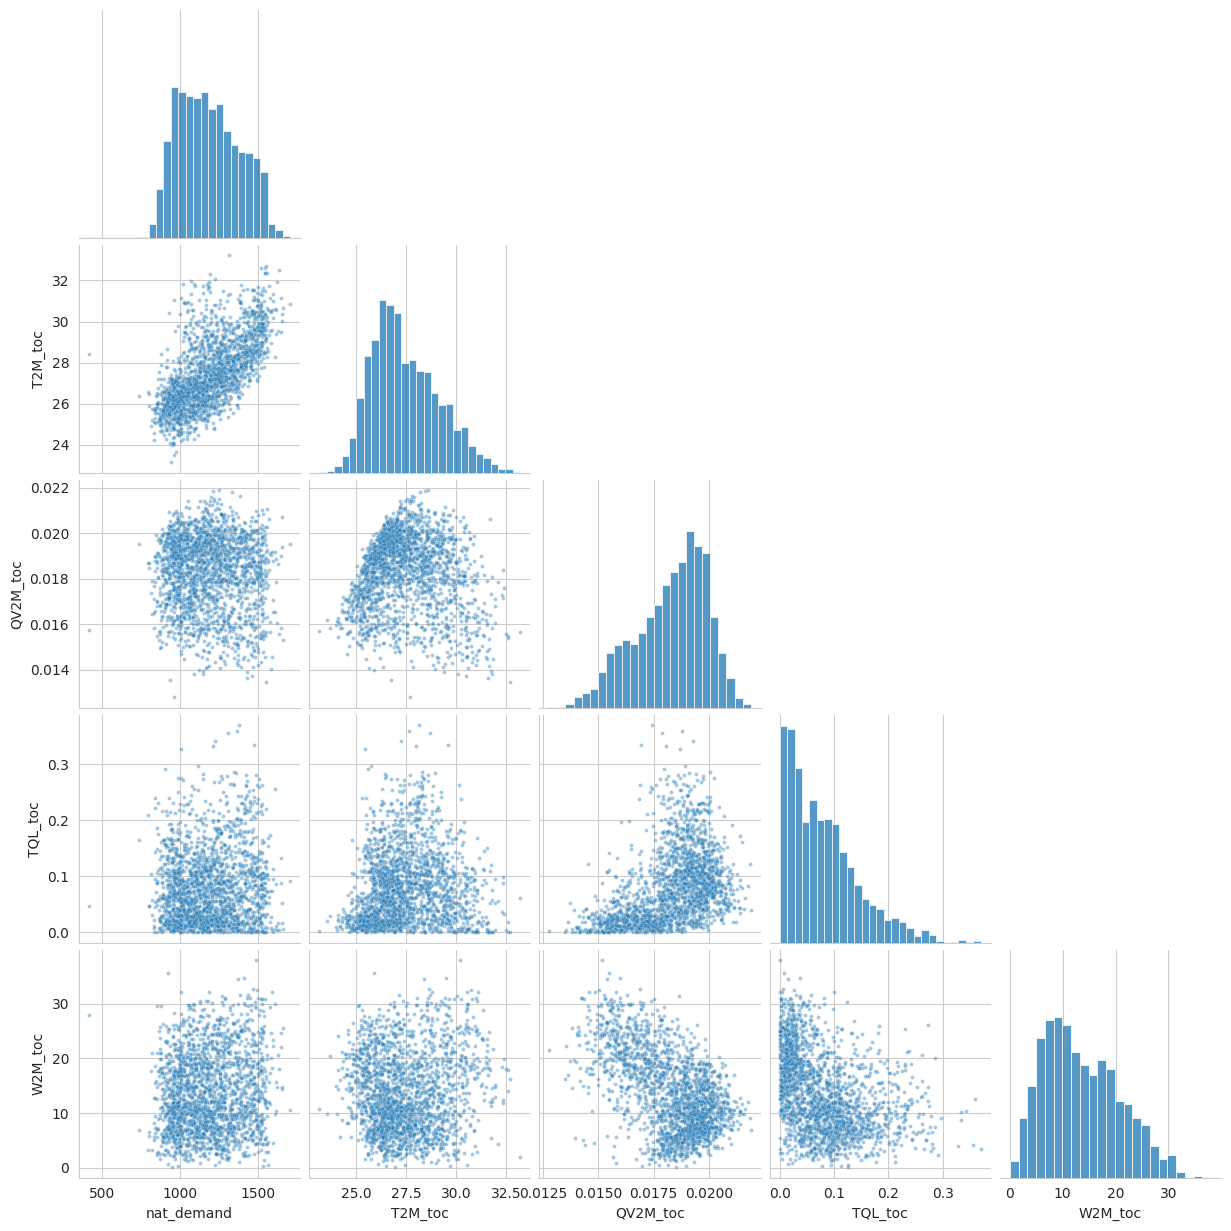

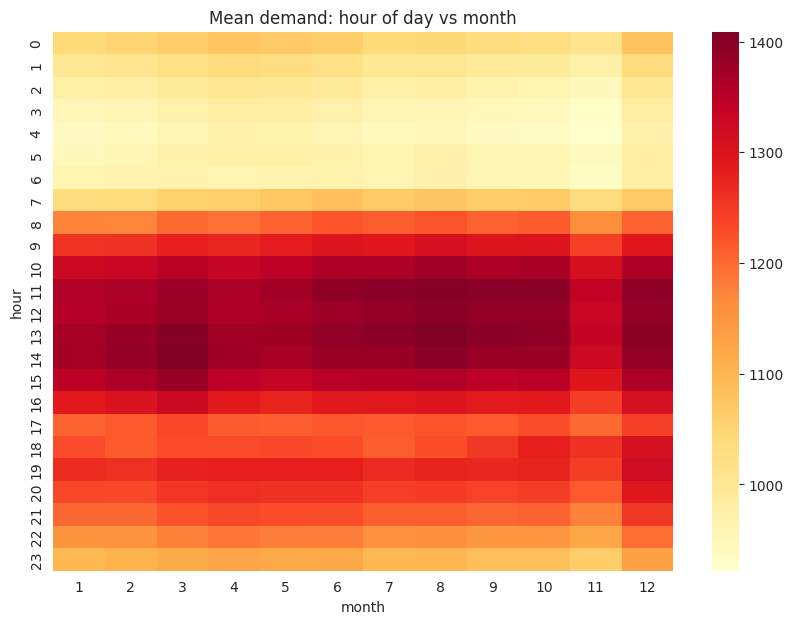

In [60]:
sns.pairplot(df[[TARGET] + weather_cols[:4]].sample(2000, random_state=1), corner=True, plot_kws={"s": 8, "alpha": 0.4})
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.pivot_table(values=TARGET, index="hour", columns="month", aggfunc="mean"), cmap="YlOrRd")
plt.title("Mean demand: hour of day vs month")
plt.show()

Components needed for 95% variance: 7 of 12


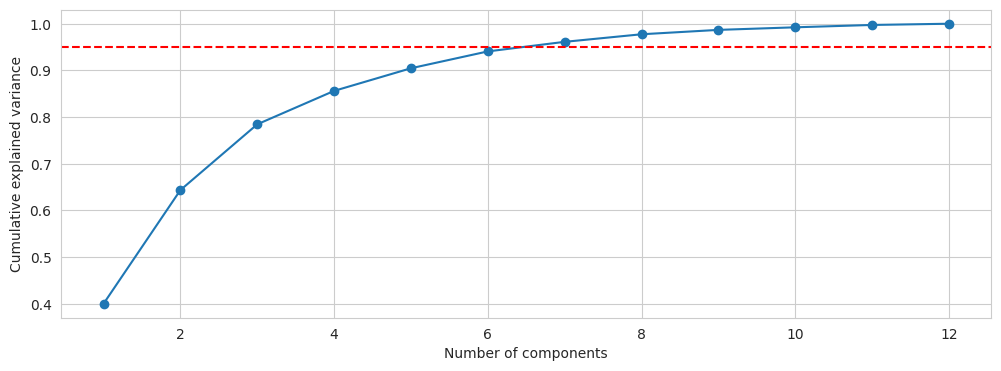

In [61]:
X = StandardScaler().fit_transform(df[weather_cols])               # standardise: PCA is scale-sensitive
pca = PCA().fit(X)
cum = pca.explained_variance_ratio_.cumsum()                       # cumulative explained variance
n95 = int(np.argmax(cum >= 0.95)) + 1
print(f"Components needed for 95% variance: {n95} of {len(weather_cols)}")

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="r", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.show()

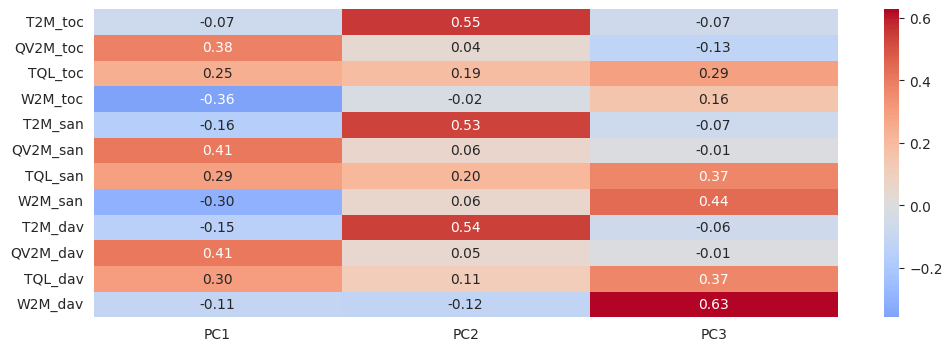

PC1   -0.126
PC2    0.645
PC3    0.017
dtype: float64


In [62]:
loadings = pd.DataFrame(pca.components_[:3].T, index=weather_cols, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)   # which variables build each component
plt.show()

scores = pd.DataFrame(pca.transform(X)[:, :3], columns=["PC1", "PC2", "PC3"])
print(scores.corrwith(df[TARGET]).round(3))                        # correlation of each component with demand